<a href="https://colab.research.google.com/github/ishwarikale44-byte/LP-3-Practical/blob/main/Copy_of_ML5miniProject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Titanic Dataset Loaded Successfully!
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0          

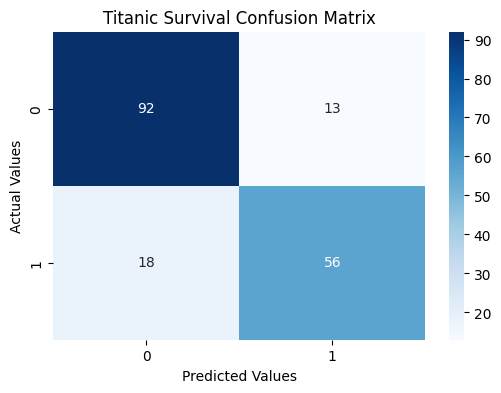

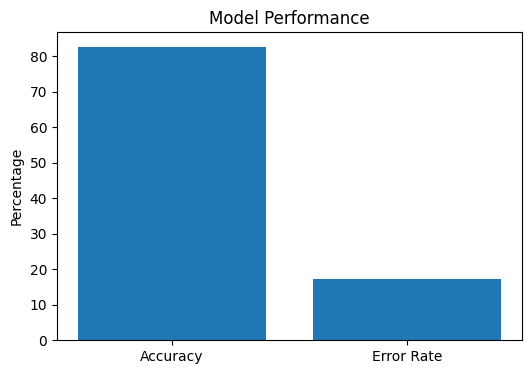


New Passenger Prediction:
Passenger will Not Survive

Experiment 7 Completed Successfully!


In [ ]:
# Titanic Survival Prediction

# Step 1: Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Step 2: Load Dataset
url = 'https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv'
df = pd.read_csv(url)

print("Titanic Dataset Loaded Successfully!")
print(df.head())

# Step 3: Dataset Information
print("\nDataset Shape:", df.shape)
print("\nMissing Values:\n", df.isnull().sum())

# Step 4: Data Preprocessing
df = df.drop(['PassengerId', 'Name', 'Ticket', 'Cabin'], axis=1)

df['Age'] = df['Age'].fillna(df['Age'].median())
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

df['Sex'] = df['Sex'].map({'male': 0, 'female': 1})
df['Embarked'] = df['Embarked'].map({'S': 0, 'C': 1, 'Q': 2})

print("\nData Preprocessing Completed!")

# Step 5: Separate Input and Output
X = df.drop('Survived', axis=1)
y = df['Survived']

# Step 6: Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("\nTraining Data:", X_train.shape)
print("Testing Data:", X_test.shape)

# Step 7: Train Random Forest Model
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

print("\nModel Training Completed!")

# Step 8: Make Predictions
y_pred = model.predict(X_test)

print("\nPredicted Values:\n", y_pred[:20])
print("\nActual Values:\n", y_test.values[:20])

# Step 9: Calculate Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("\nModel Accuracy:", accuracy * 100, "%")
print("\nClassification Report:\n", classification_report(y_test, y_pred))

# Step 10: Confusion Matrix Graph
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.title("Titanic Survival Confusion Matrix")
plt.show()

# Step 11: Accuracy and Error Rate Graph
plt.figure(figsize=(6, 4))
plt.bar(['Accuracy', 'Error Rate'],
        [accuracy * 100, (1 - accuracy) * 100])
plt.ylabel("Percentage")
plt.title("Model Performance")
plt.show()

# Step 12: Predict New Passenger Survival
new_passenger = pd.DataFrame([{
    'Pclass': 3,
    'Sex': 1,
    'Age': 25,
    'SibSp': 0,
    'Parch': 0,
    'Fare': 30,
    'Embarked': 0
}])

prediction = model.predict(new_passenger)

print("\nNew Passenger Prediction:")
if prediction[0] == 1:
    print("Passenger will Survive")
else:
    print("Passenger will Not Survive")

print("\nExperiment 7 Completed Successfully!")


In [ ]:
# Display first 10 rows in table format

print("\nTitanic Passenger Dataset:")
print(df[['Survived', 'Pclass', 'Sex', 'Age',
          'SibSp', 'Parch', 'Fare', 'Embarked']].head(10).to_string(index=False))


Titanic Passenger Dataset:
 Survived  Pclass  Sex  Age  SibSp  Parch    Fare  Embarked
        0       3    0 22.0      1      0  7.2500         0
        1       1    1 38.0      1      0 71.2833         1
        1       3    1 26.0      0      0  7.9250         0
        1       1    1 35.0      1      0 53.1000         0
        0       3    0 35.0      0      0  8.0500         0
        0       3    0 28.0      0      0  8.4583         2
        0       1    0 54.0      0      0 51.8625         0
        0       3    0  2.0      3      1 21.0750         0
        1       3    1 27.0      0      2 11.1333         0
        1       2    1 14.0      1      0 30.0708         1


In [ ]:
display(df.head(10))

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,0,22.0,1,0,7.2500,0
1,1,1,1,38.0,1,0,71.2833,1
2,1,3,1,26.0,0,0,7.9250,0
3,1,1,1,35.0,1,0,53.1000,0
4,0,3,0,35.0,0,0,8.0500,0
5,0,3,0,28.0,0,0,8.4583,2
6,0,1,0,54.0,0,0,51.8625,0
7,0,3,0,2.0,3,1,21.0750,0
8,1,3,1,27.0,0,2,11.1333,0
9,1,2,1,14.0,1,0,30.0708,1
